Tutorial: polar plots for laminate stiffness
==
Date: 30 of January 2025

Author: Saullo G. P. Castro

Cite this tutorial as:

Castro, SGP. Methods for analysis and design of composites [Computer software]. https://doi.org/10.5281/zenodo.2871782

The stiffness of a laminate depends on the direction in which it is loaded.
A polar plot of the membrane stiffness $A_{11}$ against the direction shows
at a glance where a laminate is stiff and where it is compliant, e.g. to
compare stacking sequences. This tutorial computes $A_{11}$ of a laminate in
every direction with `laminated_plate` and compares it with the closed form
of the material invariants.

The stiffness in a direction at an angle $\psi$ from the $x$ axis is that of
the laminate whose plies are rotated by $-\psi$, i.e. of the stacking
sequence `stack - psi`. With the invariants $u_1$, $u_2$, $u_3$ of the ply,
see [Ply constitutive relations and invariants](../lamina.rst), the
stiffness of a ply at the angle $\theta$ is
$q_{11L} = u_1 + u_2 \cos 2\theta + u_3 \cos 4\theta$, hence

$$
A_{11}(\psi) = \sum_k t_k \left[ u_1 + u_2 \cos 2(\theta_k - \psi) +
u_3 \cos 4(\theta_k - \psi) \right],
$$

with $t_k$ the thickness of the ply $k$.

Importing dependencies
---

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate

Defining material properties
---

In [2]:
E11 = 100e9 # [N/m^2]
E22 = 8e9 # [N/m^2]
G12 = G23 = G13 = 8e9 # [N/m^2]
nu12 = 0.29
ply_thickness = 1.25e-4 # [m]
laminaprop = E11, E22, nu12, G12, G13, G23

Creating reference laminate
---

A laminate $[-45/45/0_2/45/-45]$, stiffest along the $x$ axis, with the
$\pm 45$ plies adding stiffness in the diagonal directions.

In [3]:
stack_ref = np.asarray([-45, +45, 0, 0, +45, -45], dtype=float)

Calculating membrane stiffness $A_{11}$ in all directions
---

`laminated_plate` is called for the rotated stacking sequence in 1000
directions, and the closed form above is evaluated with the invariants
computed from the ply constants, independently of `composites`.

In [4]:
angles = np.linspace(0, 360, 1000, endpoint=False)
A11s = np.zeros_like(angles)
for i, angle in enumerate(angles):
    lam = laminated_plate(stack=stack_ref-angle, plyt=ply_thickness,
                          laminaprop=laminaprop)
    A11s[i] = lam.ABD[0, 0]

nu21 = nu12*E22/E11
Q11 = E11/(1 - nu12*nu21)
Q22 = E22/(1 - nu12*nu21)
Q12 = nu12*Q22
Q66 = G12
u1 = (3*Q11 + 3*Q22 + 2*Q12 + 4*Q66)/8
u2 = (Q11 - Q22)/2
u3 = (Q11 + Q22 - 2*Q12 - 4*Q66)/8
theta = np.deg2rad(stack_ref[:, None] - angles[None, :])
A11_ref = ply_thickness*np.sum(u1 + u2*np.cos(2*theta) + u3*np.cos(4*theta),
                               axis=0)
print('%-30s %14s %14s %10s' % ('direction', 'composites', 'closed form',
                                'rel. diff.'))
for psi in (0., 45., 90.):
    i = np.argmin(abs(angles - psi))
    print('%-30s % 14.6e % 14.6e %10.1e' % ('A11 at %g deg [N/m]' % psi,
          A11s[i], A11_ref[i], abs(A11s[i] - A11_ref[i])/A11_ref[i]))
print('largest relative difference over all directions: %.1e'
      % np.max(np.abs(A11s - A11_ref)/A11_ref))

direction                          composites    closed form rel. diff.
A11 at 0 deg [N/m]               4.334471e+07   4.334471e+07    0.0e+00
A11 at 45 deg [N/m]              3.627057e+07   3.627057e+07    0.0e+00
A11 at 90 deg [N/m]              2.018892e+07   2.018892e+07    3.7e-16
largest relative difference over all directions: 2.0e-15


Normalizing plots to keep maximum value 1 in the radial coordinate
---

In [5]:
A11_max = A11s.max()
A11s /= A11_max
A11_ref /= A11_max

Creating polar plots
---

The line is the result of `composites`, the markers the closed form in
every 25th direction.

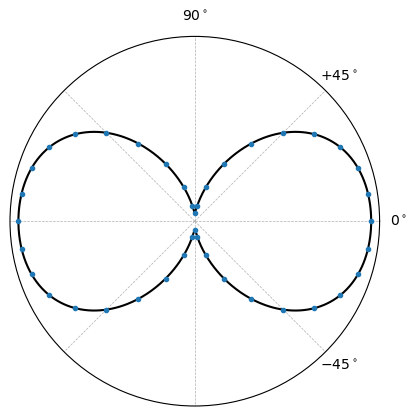

In [6]:
plt.polar(np.deg2rad(angles), A11s, 'k')
plt.polar(np.deg2rad(angles[::25]), A11_ref[::25], 'o', ms=3)
ax = plt.gca()
ax.set_yticks([])
ax.set_xticks(np.deg2rad([0, 45, 90, 135, 180, 225, 270, 315]))
ax.set_xticklabels([r"$0^\circ$", r"$+45^\circ$", r"$90^\circ$", "", "", "", "", r"$-45^\circ$"])
ax.grid(linestyle='--', lw=0.5)
plt.show()